# Training log viewer (no TensorBoard server needed)

Reads the TensorBoard event files in `lightning_logs/` directly and plots them inline.
Rerun the cells during training to refresh.

Set the runs to show in the next cell. The first cell's output lists the runs that exist.

In [1]:
import glob, io, json, os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOGDIR = "lightning_logs"
runs = sorted(os.path.relpath(os.path.dirname(f), LOGDIR) for f in glob.glob(f"{LOGDIR}/*/version_*/hparams.yaml"))
print("Available runs:", *runs, sep="\n  ")

PRETRAIN_RUN = "pretrain/version_0"
FINETUNE_RUN = "finetune_aug_llrd/version_0"

Available runs:
  finetune/version_0
  finetune_aug_llrd/version_0
  finetune_frozen/version_0
  finetune_patience5/version_0
  pretrain/version_0


In [2]:
def load_run(run):
    """Merge all event files of a run -> (scalars {tag: DataFrame(step, value)}, images {tag: [(step, png)]})."""
    scalars, images = {}, {}
    for f in sorted(glob.glob(f"{LOGDIR}/{run}/events*")):
        e = EventAccumulator(f, size_guidance={"images": 0, "scalars": 0}); e.Reload()
        for tag in e.Tags()["scalars"]:
            df = pd.DataFrame([(s.step, s.value) for s in e.Scalars(tag)], columns=["step", "value"])
            scalars[tag] = pd.concat([scalars.get(tag), df]).drop_duplicates("step", keep="last")
        for tag in e.Tags()["images"]:
            images.setdefault(tag, []).extend((im.step, im.encoded_image_string) for im in e.Images(tag))
    # Lightning logs scalars against the global step; map steps to epochs with the "epoch" scalar
    if "epoch" in scalars:
        ep = scalars["epoch"].sort_values("step").rename(columns={"value": "epoch"})
        for tag in list(scalars):
            df = scalars[tag].sort_values("step").drop(columns="epoch", errors="ignore")
            scalars[tag] = pd.merge_asof(df, ep, on="step", direction="nearest")
    return scalars, images


def plot_scalars(scalars, groups, title):
    fig, axes = plt.subplots(1, len(groups), figsize=(5.5 * len(groups), 4))
    for ax, (name, tags) in zip(axes if len(groups) > 1 else [axes], groups.items()):
        if tags == "lr-*":   # every learning-rate tag (one per optimizer param group)
            tags = sorted(t for t in scalars if t.startswith("lr-"))
        for tag in tags:
            if tag in scalars:
                df = scalars[tag].sort_values("step")
                ax.plot(df.epoch, df.value, marker="o" if len(df) < 30 else None, ms=3, label=tag)
        ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); plt.show()


def show_images(images, tag, which="last", width=12):
    """which: "last", "first", "all", or a list of epochs."""
    items = sorted(images.get(tag, []))
    if not items:
        print(f"no images logged under {tag!r}"); return
    if which == "last": items = items[-1:]
    elif which == "first": items = items[:1]
    elif which != "all": items = [it for it in items if it[0] in set(which)]
    for step, png in items:
        img = mpimg.imread(io.BytesIO(png), format="png")
        plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
        plt.imshow(img); plt.axis("off"); plt.title(f"{tag} (epoch {step})", fontsize=9); plt.show()

## Pretraining (masked reconstruction)

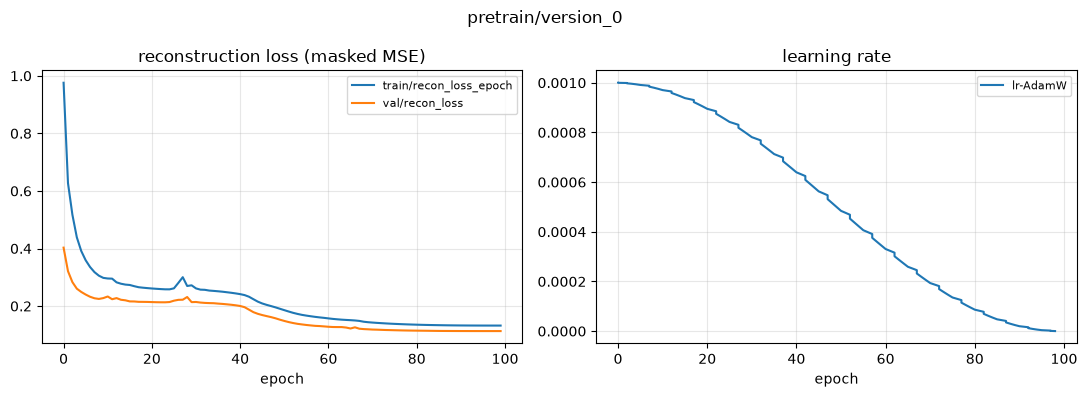

best val/recon_loss = 0.1131 at epoch 99


In [3]:
pre_scalars, pre_images = load_run(PRETRAIN_RUN)
plot_scalars(pre_scalars, {
    "reconstruction loss (masked MSE)": ["train/recon_loss_epoch", "val/recon_loss"],
    "learning rate": ["lr-AdamW"],
}, PRETRAIN_RUN)
best = pre_scalars["val/recon_loss"].sort_values("value").iloc[0]
print(f"best val/recon_loss = {best.value:.4f} at epoch {int(best.epoch)}")

Reconstructions of the same validation batch over training: first, middle and last logged epoch. Orange = blocks hidden from the encoder, red = decoder output, black = input (standardised units).

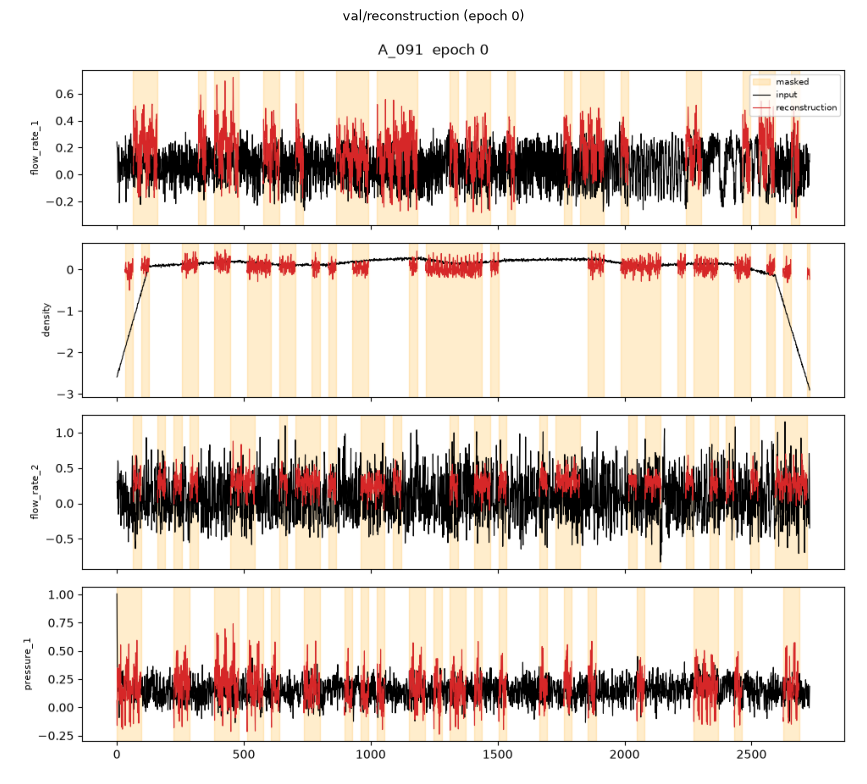

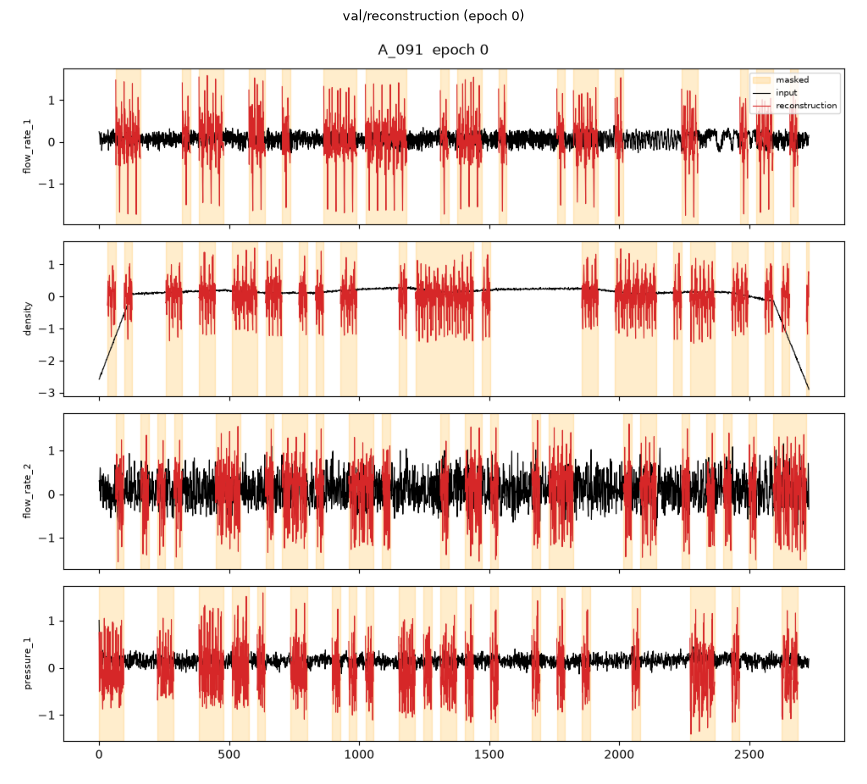

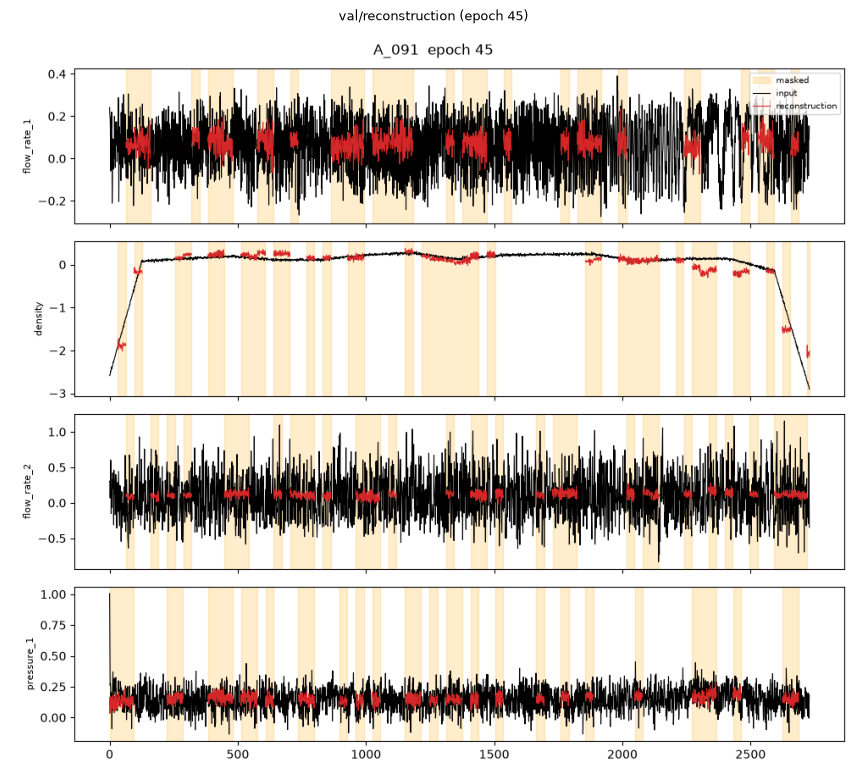

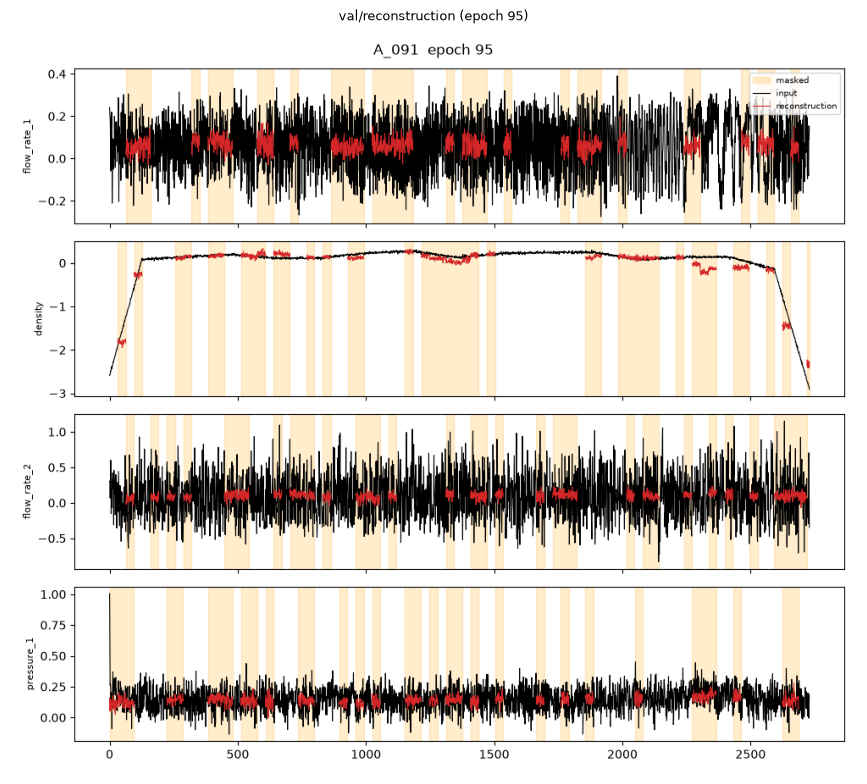

In [4]:
epochs = sorted(s for s, _ in pre_images.get("val/reconstruction", []))
if epochs:
    show_images(pre_images, "val/reconstruction", which=[epochs[0], epochs[len(epochs) // 2], epochs[-1]], width=11)

## Finetuning (classification)

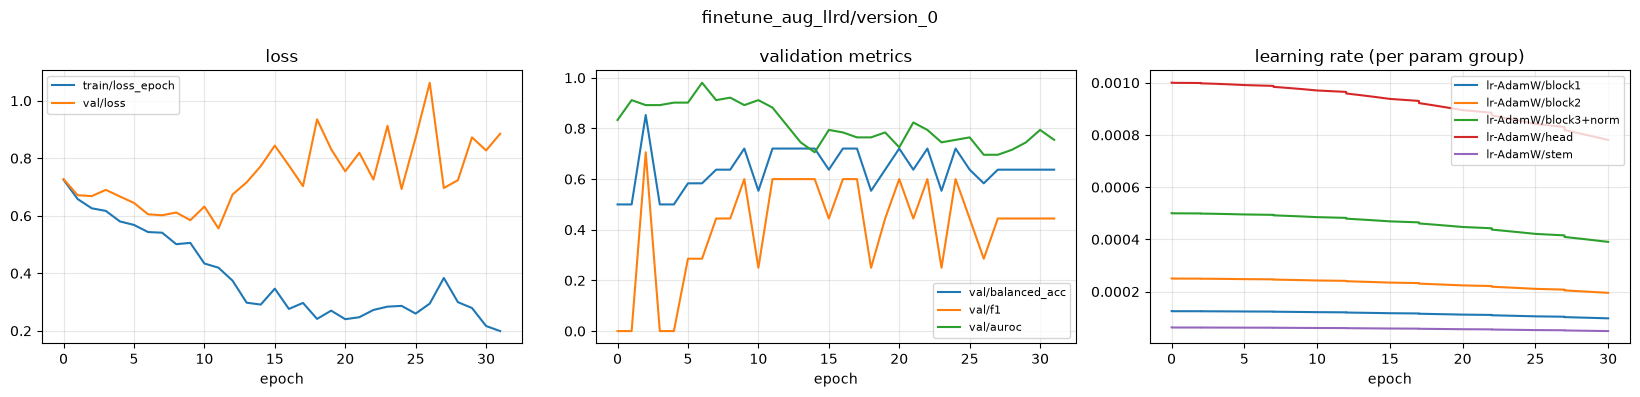

best val/loss = 0.5559 at epoch 11 (this checkpoint is used for the test set)


In [5]:
ft_scalars, ft_images = load_run(FINETUNE_RUN)
plot_scalars(ft_scalars, {
    "loss": ["train/loss_epoch", "val/loss"],
    "validation metrics": ["val/balanced_acc", "val/f1", "val/auroc"],
    "learning rate (per param group)": "lr-*",
}, FINETUNE_RUN)
best = ft_scalars["val/loss"].sort_values("value").iloc[0]
print(f"best val/loss = {best.value:.4f} at epoch {int(best.epoch)} (this checkpoint is used for the test set)")

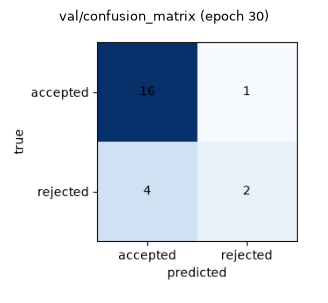

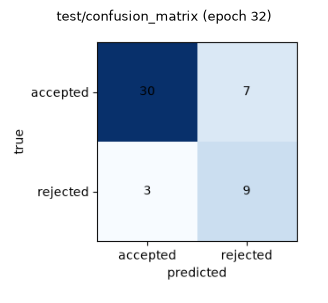

In [6]:
show_images(ft_images, "val/confusion_matrix", which="last", width=4)
show_images(ft_images, "test/confusion_matrix", which="last", width=4)

## Test results

,test (positive class = rejected)
acc,0.796
balanced_acc,0.780
precision,0.562
recall,0.750
f1,0.643
auroc,0.847


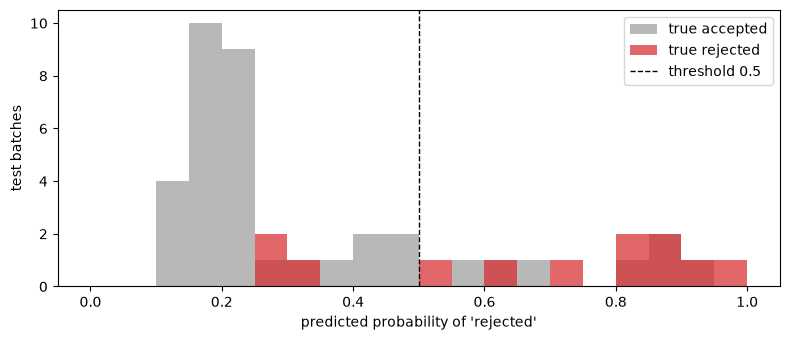

Misclassified test batches:


,batch_id,label,p_rejected,predicted
11,A_100,1,0.252412,0
26,A_202,1,0.286652,0
24,A_197,1,0.339211,0
3,A_053,0,0.597748,1
9,A_090,0,0.618543,1
35,A_253,0,0.688090,1
0,A_005,0,0.843415,1
19,A_156,0,0.868984,1
13,A_114,0,0.877139,1
1,A_011,0,0.904374,1


In [7]:
run_dir = f"{LOGDIR}/{FINETUNE_RUN}"
if os.path.exists(f"{run_dir}/test_metrics.json"):
    metrics = json.load(open(f"{run_dir}/test_metrics.json"))
    display(pd.Series(metrics, name="test (positive class = rejected)").round(3).to_frame())
    preds = pd.read_csv(f"{run_dir}/test_predictions.csv")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for lab, name, c in [(0, "accepted", "#9a9a9a"), (1, "rejected", "#d62728")]:
        ax.hist(preds.p_rejected[preds.label == lab], bins=20, range=(0, 1), alpha=0.7, color=c, label=f"true {name}")
    ax.axvline(0.5, color="k", ls="--", lw=1, label="threshold 0.5")
    ax.set_xlabel("predicted probability of 'rejected'"); ax.set_ylabel("test batches"); ax.legend()
    plt.tight_layout(); plt.show()
    print("Misclassified test batches:")
    display(preds[preds.label != preds.predicted].sort_values("p_rejected"))
else:
    print("no test_metrics.json in", run_dir)

## Compare all finetuning runs

Test scores of every run that has a `test_metrics.json`, plus how many epochs it trained and which epoch was used. Positive class = rejected.

In [8]:
rows = []
for f in sorted(glob.glob(f"{LOGDIR}/*/version_*/test_metrics.json")):
    run = os.path.relpath(os.path.dirname(f), LOGDIR)
    row = {"run": run, **json.load(open(f))}
    hp = open(os.path.join(os.path.dirname(f), "hparams.yaml")).read()
    row["encoder"] = "frozen" if "freeze_encoder: true" in hp else "finetuned"
    ld = [l.split(":", 1)[1].strip() for l in hp.splitlines() if l.startswith("layer_decay:")]
    row["layer_decay"] = ld[0] if ld and ld[0] != "null" else "-"
    row["augment"] = "augment:" in hp and "augment: null" not in hp
    row["pretrained"] = "pretrained_ckpt: null" not in hp
    sc, _ = load_run(run)
    if "val/loss" in sc:
        v = sc["val/loss"]
        row["epochs_trained"] = len(v)
        row["best_epoch"] = int(v.sort_values("value").iloc[0].epoch)
    rows.append(row)
cols = ["run", "encoder", "layer_decay", "augment", "pretrained", "epochs_trained", "best_epoch",
        "f1", "precision", "recall", "balanced_acc", "acc", "auroc"]
comparison = pd.DataFrame(rows)[cols].set_index("run").round(3)
comparison

,encoder,layer_decay,augment,pretrained,epochs_trained,best_epoch,f1,precision,recall,balanced_acc,acc,auroc
run,,,,,,,,,,,,
finetune/version_0,finetuned,-,False,True,35,14,0.667,0.600,0.750,0.794,0.816,0.869
finetune_aug_llrd/version_0,finetuned,0.5,True,True,32,11,0.643,0.562,0.750,0.780,0.796,0.847
finetune_frozen/version_0,frozen,-,False,True,98,77,0.421,0.571,0.333,0.626,0.776,0.800
finetune_patience5/version_0,finetuned,-,False,True,20,14,0.667,0.600,0.750,0.794,0.816,0.869
